In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

PERCORSO = '/content/drive/MyDrive/ndvi_frumento_mais_2022.csv'
df = pd.read_csv(PERCORSO)

print('Righe e colonne:', df.shape)
print()
print(df.dtypes)
print()
print(df.head())

Righe e colonne: (17229, 5)

system:index     object
classe            int64
data             object
ndvi            float64
.geo             object
dtype: object

             system:index  classe        data      ndvi  \
0  0_00000000000000000001       1  2021-10-01  0.115141   
1  0_00000000000000000002       1  2021-10-01  0.067454   
2  0_00000000000000000003       1  2021-10-01  0.116766   
3  0_00000000000000000005       1  2021-10-01  0.117214   
4  0_00000000000000000006       1  2021-10-01 -0.084239   

                                     .geo  
0  {"type":"MultiPoint","coordinates":[]}  
1  {"type":"MultiPoint","coordinates":[]}  
2  {"type":"MultiPoint","coordinates":[]}  
3  {"type":"MultiPoint","coordinates":[]}  
4  {"type":"MultiPoint","coordinates":[]}  


In [3]:
print('Valori mancanti:\n', df.isna().sum())
print('\nRighe per classe:\n', df['classe'].value_counts())
print('\nRange NDVI:', df['ndvi'].min(), '-', df['ndvi'].max())
print('\nNumero di date distinte:', df['data'].nunique())

Valori mancanti:
 system:index    0
classe          0
data            0
ndvi            0
.geo            0
dtype: int64

Righe per classe:
 classe
2    8622
1    8607
Name: count, dtype: int64

Range NDVI: -0.1152882203459739 - 0.9961758852005004

Numero di date distinte: 38


In [4]:
df['data'] = pd.to_datetime(df['data'])
df['coltura'] = df['classe'].map({1: 'Frumento tenero', 2: 'Mais'})

print(df.dtypes)
print(df[['data', 'coltura', 'ndvi']].head())


system:index            object
classe                   int64
data            datetime64[ns]
ndvi                   float64
.geo                    object
coltura                 object
dtype: object
        data          coltura      ndvi
0 2021-10-01  Frumento tenero  0.115141
1 2021-10-01  Frumento tenero  0.067454
2 2021-10-01  Frumento tenero  0.116766
3 2021-10-01  Frumento tenero  0.117214
4 2021-10-01  Frumento tenero -0.084239


In [5]:
agg = (df.groupby(['coltura', 'data'])['ndvi']
         .agg(mediana='median',
              q25=lambda x: x.quantile(0.25),
              q75=lambda x: x.quantile(0.75),
              n='count')
         .reset_index())

print(agg.shape)
print(agg.head(10))


(76, 6)
           coltura       data   mediana       q25       q75    n
0  Frumento tenero 2021-10-01  0.115141  0.089623  0.187755  149
1  Frumento tenero 2021-10-11  0.121713  0.099377  0.151900  250
2  Frumento tenero 2021-10-21  0.099467  0.075581  0.131303  241
3  Frumento tenero 2021-10-31  0.138316  0.110060  0.173679  248
4  Frumento tenero 2021-11-10  0.083366  0.021922  0.139535    5
5  Frumento tenero 2021-11-20  0.308935  0.243808  0.377411  250
6  Frumento tenero 2021-11-30  0.499799  0.381069  0.623633  127
7  Frumento tenero 2021-12-10  0.441345  0.352085  0.519154  250
8  Frumento tenero 2021-12-30  0.536725  0.431568  0.620095  250
9  Frumento tenero 2022-01-09  0.600143  0.503172  0.691906  250


In [6]:
print(agg[agg['n'] < 150].sort_values('data'))
print('\nDate con n basso:', (agg['n'] < 150).sum(), 'su', len(agg))


            coltura       data   mediana       q25       q75    n
0   Frumento tenero 2021-10-01  0.115141  0.089623  0.187755  149
4   Frumento tenero 2021-11-10  0.083366  0.021922  0.139535    5
42             Mais 2021-11-10 -0.008991 -0.011004  0.002364    3
6   Frumento tenero 2021-11-30  0.499799  0.381069  0.623633  127
44             Mais 2021-11-30  0.198851  0.155665  0.305437  127
10  Frumento tenero 2022-01-19  0.316649  0.260676  0.421387   14
48             Mais 2022-01-19  0.092271  0.079571  0.197081   17
25  Frumento tenero 2022-06-18  0.230054  0.203090  0.253770  145
63             Mais 2022-06-18  0.748536  0.703738  0.792378  140

Date con n basso: 9 su 76


In [7]:
piv = agg.pivot(index='data', columns='coltura', values='mediana')
piv['distanza'] = (piv['Mais'] - piv['Frumento tenero']).abs()
print(piv.sort_values('distanza', ascending=False).head(5).to_string())
print()
print(piv.sort_values('distanza').head(5).to_string())

coltura     Frumento tenero      Mais  distanza
data                                           
2022-04-19         0.907977  0.112527  0.795451
2022-04-29         0.901914  0.113196  0.788719
2022-04-09         0.840118  0.128054  0.712065
2022-03-30         0.830903  0.119777  0.711126
2022-05-09         0.890706  0.185169  0.705537

coltura     Frumento tenero      Mais  distanza
data                                           
2022-09-16         0.100708  0.104603  0.003894
2022-10-06         0.091570  0.086249  0.005322
2021-10-01         0.115141  0.109480  0.005661
2022-09-26         0.104637  0.098792  0.005845
2022-10-16         0.099983  0.091460  0.008523


In [8]:
agg90 = (df.groupby(['coltura', 'data'])['ndvi']
           .agg(mediana='median',
                q75=lambda x: x.quantile(0.75),
                q90=lambda x: x.quantile(0.90),
                q95=lambda x: x.quantile(0.95),
                n='count')
           .reset_index())

agg90 = agg90[agg90['n'] >= 30]

fr_aut = agg90[(agg90['coltura'] == 'Frumento tenero') &
               (agg90['data'] >= '2022-07-15')].sort_values('data')

print(fr_aut[['data', 'mediana', 'q75', 'q90', 'q95', 'n']].to_string(index=False))


      data  mediana      q75      q90      q95   n
2022-07-18 0.145952 0.173410 0.214418 0.276991 250
2022-07-28 0.124084 0.159354 0.219614 0.290454 250
2022-08-07 0.111237 0.161256 0.212164 0.322015 250
2022-08-17 0.094015 0.139135 0.244335 0.405383 250
2022-08-27 0.108551 0.163053 0.419753 0.630053 247
2022-09-06 0.103230 0.157734 0.472335 0.681079 250
2022-09-16 0.100708 0.150741 0.487993 0.677275 224
2022-09-26 0.104637 0.134746 0.375580 0.513608 248
2022-10-06 0.091570 0.119006 0.283679 0.438753 250
2022-10-16 0.099983 0.132023 0.202108 0.294113 245


In [9]:
print(agg[(agg['data'] > '2021-10-25') & (agg['data'] < '2021-11-20')].to_string())

            coltura       data   mediana       q25       q75    n
3   Frumento tenero 2021-10-31  0.138316  0.110060  0.173679  248
4   Frumento tenero 2021-11-10  0.083366  0.021922  0.139535    5
41             Mais 2021-10-31  0.126543  0.106921  0.154989  249
42             Mais 2021-11-10 -0.008991 -0.011004  0.002364    3


In [10]:
N_MINIMO = 30

print('Righe escluse:')
print(agg[agg['n'] < N_MINIMO][['coltura', 'data', 'mediana', 'n']].to_string())

agg = agg[agg['n'] >= N_MINIMO].copy()
print('\nRighe rimaste:', len(agg))

Righe escluse:
            coltura       data   mediana   n
4   Frumento tenero 2021-11-10  0.083366   5
10  Frumento tenero 2022-01-19  0.316649  14
42             Mais 2021-11-10 -0.008991   3
48             Mais 2022-01-19  0.092271  17

Righe rimaste: 72


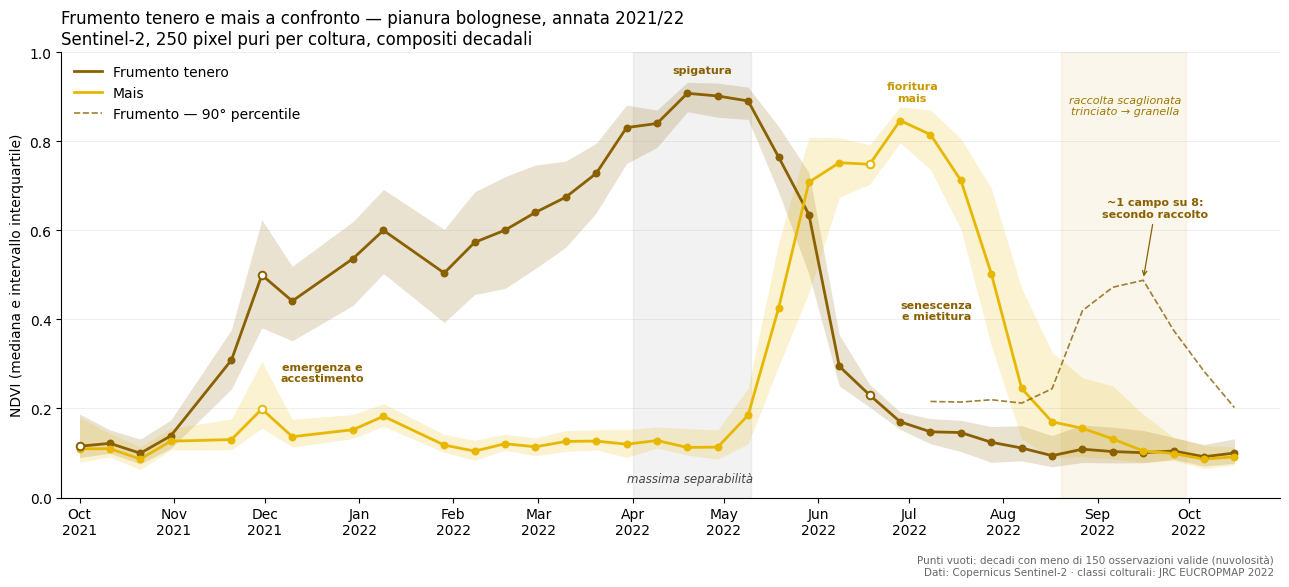

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SOGLIA_N = 150
COLORI = {'Frumento tenero': '#8a6000', 'Mais': '#e8b800'}

fig, ax = plt.subplots(figsize=(13, 6))

for coltura, g in agg.groupby('coltura'):
    g = g.sort_values('data')
    c = COLORI[coltura]

    # banda interquartile
    ax.fill_between(g['data'], g['q25'], g['q75'], color=c, alpha=0.18, linewidth=0)

    # linea della mediana
    ax.plot(g['data'], g['mediana'], color=c, linewidth=2, label=coltura, zorder=3)

    # punti: pieni se robusti, vuoti se n < soglia
    solidi  = g[g['n'] >= SOGLIA_N]
    fragili = g[g['n'] <  SOGLIA_N]
    ax.scatter(solidi['data'], solidi['mediana'], color=c, s=22, zorder=4)
    ax.scatter(fragili['data'], fragili['mediana'], facecolors='white',
               edgecolors=c, s=30, linewidths=1.4, zorder=5)

# finestra di massima separabilità
ax.axvspan(pd.Timestamp('2022-04-01'), pd.Timestamp('2022-05-10'),
           color='grey', alpha=0.10, zorder=0)
ax.text(pd.Timestamp('2022-04-20'), 0.035, 'massima separabilità',
        ha='center', fontsize=8.5, style='italic', color='#444444')

ax.set_ylim(0, 1)
ax.set_ylabel('NDVI (mediana e intervallo interquartile)')
ax.set_xlabel('')
ax.set_title('Frumento tenero e mais a confronto — pianura bolognese, annata 2021/22\n'
             'Sentinel-2, 250 pixel puri per coltura, compositi decadali',
             fontsize=12, loc='left')

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.set_xlim(pd.Timestamp('2021-09-25'), pd.Timestamp('2022-10-31'))
ax.grid(axis='y', alpha=0.25, linewidth=0.6)
for lato in ['top', 'right']:
    ax.spines[lato].set_visible(False)

ax.legend(frameon=False, loc='upper left')
ax.text(0.995, -0.13,
        'Punti vuoti: decadi con meno di 150 osservazioni valide (nuvolosità)\n'
        'Dati: Copernicus Sentinel-2 · classi colturali: JRC EUCROPMAP 2022',
        transform=ax.transAxes, ha='right', va='top', fontsize=7.5, color='#666666')

# --- fasi fenologiche ---
FASI = [
    ('2021-12-20', 0.28, 'emergenza e\naccestimento', '#8a6000'),
    ('2022-04-24', 0.96, 'spigatura',                 '#8a6000'),
    ('2022-07-10', 0.42, 'senescenza\ne mietitura',   '#8a6000'),
    ('2022-07-02', 0.91, 'fioritura\nmais',           '#c89800'),
]

for data, y, testo, colore in FASI:
    ax.annotate(testo, xy=(pd.Timestamp(data), y),
                ha='center', va='center', fontsize=8,
                color=colore, fontweight='bold')

# --- fascia della raccolta del mais ---
ax.axvspan(pd.Timestamp('2022-08-20'), pd.Timestamp('2022-09-30'),
           color='#c89800', alpha=0.08, zorder=0)
ax.text(pd.Timestamp('2022-09-10'), 0.86,
        'raccolta scaglionata\ntrinciato → granella',
        ha='center', fontsize=8, color='#a07800', style='italic')

# --- 90° percentile frumento (secondo raccolto) ---
fr90 = agg90[(agg90['coltura'] == 'Frumento tenero') &
             (agg90['data'] >= '2022-07-01')].sort_values('data')

ax.plot(fr90['data'], fr90['q90'], color='#8a6000', linewidth=1.2,
        linestyle='--', alpha=0.8, zorder=3,
        label='Frumento — 90° percentile')

ax.annotate('~1 campo su 8:\nsecondo raccolto',
            xy=(pd.Timestamp('2022-09-16'), 0.49),
            xytext=(pd.Timestamp('2022-09-20'), 0.63),
            fontsize=8, color='#8a6000', fontweight='bold', ha='center',
            arrowprops=dict(arrowstyle='->', color='#8a6000', lw=0.9))

ax.legend(frameon=False, loc='upper left')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/ndvi_frumento_mais_2022.png', dpi=200,
            bbox_inches='tight')
plt.show()

In [12]:
set22 = df[(df['coltura'] == 'Frumento tenero') &
           (df['data'] >= '2022-09-01') & (df['data'] <= '2022-09-30')]
quota = (set22.groupby('data')['ndvi']
              .apply(lambda x: (x > 0.40).mean() * 100).round(1))
print('Percentuale di punti frumento con NDVI > 0.40 in settembre:')
print(quota.to_string())

Percentuale di punti frumento con NDVI > 0.40 in settembre:
data
2022-09-06    13.2
2022-09-16    13.8
2022-09-26    10.1
